<img src="logos/Logo_de_la_Facultad_Experimental_de_Ciencia_y_Tecnología.svg.png"
     width="250"
     style="display: block; margin-left: auto; margin-right: auto;">

<div align="center">

**UNIVERSIDAD DE CARABOBO**
Facultad Experimental de Ciencia y Tecnología
Departamento de Computación
Aprendizaje Automático

# Minecraft Composting — Modeling and Model Selection
### Assignment 3: fair model comparison, hyperparameter optimization with Optuna and a single test evaluation

</div>

**Professor:** Álvaro Espinoza &nbsp;|&nbsp; **Students:** Jesús Redondo (31499459), Joshtin Mejías (31071016) &nbsp;|&nbsp; **Year:** 2026

---

This notebook closes the workflow started in `01_eda.ipynb` and `02_data_preparation.ipynb`. It answers one question
with evidence: **which complete pipeline (preparation + model) generalizes best to new composting sessions, and why is
that choice defensible?** The goal is not the highest number by any means, but a selection that survives the variation
between folds.

> **Contract between notebooks.** Notebook 02 saved `artifacts/split_manifest.csv` and
> `artifacts/data_preparation_metadata.json`. This notebook rebuilds the data from the 16 raw files, re-creates the
> split and the attempt-level labels, and **stops** if they differ from those artifacts. No fitted object or
> transformed matrix is reused: every pipeline learns its preprocessing inside each fold.

> **Limitation.** The EDA examined all 48,000 sessions before the split, so the test set is useful to check the
> workflow and estimate generalization for the course, but it is not a fully independent final test.

# 1. Objective, Metric and Evaluation Protocol

| Element | Decision |
|---|---|
| **Problem type** | Binary **classification** of one composting attempt: `level_increased` = 1 if the item raises the composter's level. |
| **Inputs** | Only what exists before the item goes in (notebook 02): the `material` and whether the composter is empty (`composter_empty`). |
| **Primary metric** | **Log loss** (cross-entropy) of the predicted probability, averaged over attempts — lower is better. |
| **Secondary metrics** | Brier score (squared error of the probability), ROC AUC (ranking), accuracy and F1 of the positive class at threshold 0.5. |
| **Data used for decisions** | Only the training sessions, through cross-validation. Test is used once, at the end. |
| **Validation** | 5-fold cross-validation **grouped by session** and stratified by material (Section 4); the same folds for every model, variant and Optuna trial. |
| **Selection rule** | Lowest mean CV log loss; among pipelines within **one standard error** of the best, the simplest one. Complexity order, fixed here: representations `material_no_empty` < `material` < `tier` = `chance` (target encodings); models logistic regression < decision tree < gradient boosting < random forest < MLP, a tuned configuration slightly above its initial one. |

**Why log loss.** What the model produces is a probability — *how likely is this item to raise the level now?* — and
the EDA showed that the outcome is essentially a dice roll with a material-specific chance. Log loss charges
$-\log \hat p$ for the outcome that actually happened, so it measures exactly the real error of such a prediction:
being confident and wrong. It is a proper scoring rule: it is minimized only by the true probabilities.

**Why accuracy and F1 are only secondary.** With two inputs there are only 32 distinct attempts (16 materials ×
empty / not empty). Any reasonable model then predicts the same class for every attempt of a material, so accuracy and
F1 only depend on which side of 0.5 each material falls. `Cactus` and `Sugar Cane` sit at ≈ 0.50, so those metrics can
flip between models because of noise. The classes are near-balanced (≈ 48% / 52%), so no class weighting or resampling
is used: it would distort the probabilities that the primary metric evaluates.

**Reference values** (computed in Section 5 on the training data): the class prior (`DummyClassifier`) and the
**irreducible error** — the log loss of the exact per-(material, empty) success rates, which no model using these
inputs can beat on average.

# 2. Imports, Configuration and Data

**Motivation.** All values that control the experiment (seeds, folds, Optuna budget) are defined once. The data is
rebuilt from the raw files with the same code as notebook 02 and verified against its artifacts before anything is
fitted.

In [1]:
import hashlib
import json
import platform
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, brier_score_loss, classification_report,
                             f1_score, log_loss, roc_auc_score)
from sklearn.model_selection import (StratifiedGroupKFold, StratifiedKFold, cross_val_predict, cross_validate,
                                     train_test_split)
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

# --- Experiment configuration ---------------------------------------------------------
N_FOLDS = 5                      # Section 4
N_JOBS = N_FOLDS                 # the 5 folds of one cross-validation run in parallel
HGB_TRIALS, MLP_TRIALS = 30, 15  # Optuna budget = number of trials (Section 7)
STUDY_TIMEOUT_S = 30 * 60        # safety net only; if reached, results would depend on the machine
SUCCESSES_REQUIRED = 7
EXPECTED_ROWS_PER_FILE = 3_000
SUGAR_CANE_ANOMALY = ("Sugar Cane", 339, 398)

# --- Paths (works from the repo root or from notebooks/) ------------------------------
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_DIR = PROJECT_ROOT / "data"
SPLIT_MANIFEST_PATH = PROJECT_ROOT / "artifacts" / "split_manifest.csv"
METADATA_PATH = PROJECT_ROOT / "artifacts" / "data_preparation_metadata.json"
missing = [str(p) for p in (DATA_DIR, SPLIT_MANIFEST_PATH, METADATA_PATH) if not p.exists()]
if missing:
    raise FileNotFoundError(f"Run 02_data_preparation.ipynb first; missing: {missing}")

with METADATA_PATH.open(encoding="utf-8") as metadata_file:
    METADATA = json.load(metadata_file)
RANDOM_STATE = int(METADATA["random_state"])
TEST_SIZE = float(METADATA["test_size"])
TARGET = METADATA["target_column"]
EXPANSION_SEEDS = METADATA["expansion_seeds"]
TARGET_ENCODING_FOLDS = int(METADATA["target_encoding"]["folds"])

RAW_FILES = {
    "Apple_v2.csv": "Apple", "Cactus_v2.csv": "Cactus", "Carrot_v2.csv": "Carrot", "Cookie_v2.csv": "Cookie",
    "Melon_v2.csv": "Melon", "Melonseed_v2.csv": "Melon Seeds", "Oakleaf_v2.csv": "Oak Leaves",
    "Oaksapling_v2.csv": "Oak Sapling", "Potato_v2.csv": "Potato", "Pumpkin_v2.csv": "Pumpkin",
    "Pumpkinseed_v2.csv": "Pumpkin Seeds", "Radish_v2.csv": "Radish", "Radishseed_v2.csv": "Radish Seeds",
    "Sugarcane_v2.csv": "Sugar Cane", "Wheat_v2.csv": "Wheat", "Wheatseed_v2.csv": "Wheat Seeds",
}
VALID_MATERIALS = sorted(RAW_FILES.values())

# --- Display ---------------------------------------------------------------------------
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
pd.set_option("display.float_format", "{:.5f}".format)
sns.set_theme(style="whitegrid", context="notebook")
sklearn.set_config(display="text")
optuna.logging.set_verbosity(optuna.logging.WARNING)   # one summary per study instead of one line per trial
SERIES_1, SERIES_2, INK_MUTED = "#2a78d6", "#eb6834", "#52514e"

print(f"Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__} | "
      f"scikit-learn {sklearn.__version__} | optuna {optuna.__version__}")
print(f"Seed {RANDOM_STATE} | test share {TEST_SIZE:.0%} | target '{TARGET}'")

Python 3.12.13 | pandas 3.0.5 | numpy 2.5.2 | scikit-learn 1.9.1 | optuna 5.0.0
Seed 42 | test share 20% | target 'level_increased'


### Rebuild the split and the attempt tables from the raw files

The functions below are **copied verbatim from notebook 02** (a notebook cannot import another notebook's
variables). The next cell then proves that the copy reproduces notebook 02 exactly.

In [2]:
def check(condition, message):
    """Raise a readable error when a validation rule fails; return the message when it passes."""
    if not bool(condition):
        raise ValueError(f"Validation failed: {message}")
    return message


def load_sessions(data_dir, raw_files):
    """Read the 16 raw files (one integer column each) into one session-level table."""
    missing = [f for f in raw_files if not (data_dir / f).exists()]
    check(not missing, f"all raw files are present (missing: {missing})")
    frames = []
    for fname, material in raw_files.items():
        raw = pd.read_csv(data_dir / fname)
        check(raw.shape[1] == 1, f"{fname} has exactly one column (found {raw.shape[1]})")
        frames.append(pd.DataFrame({
            "material": material,
            "trial_id": np.arange(len(raw)),
            "items_used": raw.iloc[:, 0].to_numpy(),
        }))
    sessions = pd.concat(frames, ignore_index=True)
    sessions["session_id"] = np.arange(len(sessions))
    return sessions[["session_id", "material", "trial_id", "items_used"]]


def expand_sessions_to_attempts(session_table, seed):
    """One row per item insertion. Learns nothing from the data: each session uses only its own length."""
    lengths = session_table["items_used"].to_numpy()
    attempts = pd.DataFrame({
        "session_id": np.repeat(session_table["session_id"].to_numpy(), lengths),
        "material": np.repeat(session_table["material"].to_numpy(), lengths),
        "attempt_number": np.concatenate([np.arange(1, n + 1) for n in lengths]),
        "session_length": np.repeat(lengths, lengths),
    })
    is_first = attempts["attempt_number"] == 1
    is_last = attempts["attempt_number"] == attempts["session_length"]
    is_middle = ~is_first & ~is_last
    rng = np.random.default_rng(seed)
    random_rank = (
        pd.Series(rng.random(len(attempts)), index=attempts.index)[is_middle]
        .groupby(attempts.loc[is_middle, "session_id"])
        .rank(method="first")
    )
    attempts["level_increased"] = (is_first | is_last).astype(int)
    attempts.loc[random_rank[random_rank <= SUCCESSES_REQUIRED - 2].index, "level_increased"] = 1
    return attempts.drop(columns=["session_length"])


def validate_attempts(attempts, session_table, name):
    successes = attempts.groupby("session_id")["level_increased"].sum()
    return [
        check("level_increased" in attempts.columns, f"{name}: target column present"),
        check(attempts["level_increased"].isin([0, 1]).all(), f"{name}: target is binary 0/1"),
        check(len(attempts) == session_table["items_used"].sum(), f"{name}: one row per inserted item"),
        check(successes.eq(SUCCESSES_REQUIRED).all(), f"{name}: exactly {SUCCESSES_REQUIRED} successes per session"),
        check(attempts.loc[attempts["attempt_number"] == 1, "level_increased"].eq(1).all(),
              f"{name}: every first attempt (empty composter) is a success"),
    ]


sessions = load_sessions(DATA_DIR, RAW_FILES)
check(len(sessions) == len(RAW_FILES) * EXPECTED_ROWS_PER_FILE, "48,000 sessions loaded")
check(sessions.notna().all().all() and (sessions["items_used"] >= SUCCESSES_REQUIRED).all(),
      "no missing values and items_used >= 7")

train_sessions, test_sessions = train_test_split(
    sessions, test_size=TEST_SIZE, stratify=sessions["material"], random_state=RANDOM_STATE)
train_sessions = train_sessions.sort_values("session_id").reset_index(drop=True)
test_sessions = test_sessions.sort_values("session_id").reset_index(drop=True)

train_attempts = expand_sessions_to_attempts(train_sessions, seed=EXPANSION_SEEDS["train"])
test_attempts = expand_sessions_to_attempts(test_sessions, seed=EXPANSION_SEEDS["test"])
X_train, y_train = train_attempts.drop(columns=[TARGET]), train_attempts[TARGET]
X_test, y_test = test_attempts.drop(columns=[TARGET]), test_attempts[TARGET]
print(f"Train: {len(train_sessions):,} sessions -> {len(X_train):,} attempts | "
      f"Test (reserved): {len(test_sessions):,} sessions -> {len(X_test):,} attempts")

Train: 38,400 sessions -> 555,828 attempts | Test (reserved): 9,600 sessions -> 139,595 attempts


In [3]:
def attempts_fingerprint(attempts):
    """SHA-256 of (session_id, attempt_number, level_increased): detects any change in the synthetic labels."""
    hashed = pd.util.hash_pandas_object(attempts[["session_id", "attempt_number", TARGET]], index=False)
    return hashlib.sha256(hashed.to_numpy().tobytes()).hexdigest()


expected_manifest = pd.read_csv(SPLIT_MANIFEST_PATH)
rebuilt_manifest = (
    pd.concat([train_sessions.assign(split="train"), test_sessions.assign(split="test")])
    [["session_id", "material", "trial_id", "split"]]
    .sort_values("session_id").reset_index(drop=True)
)
contract = [
    check(list(expected_manifest.columns) == ["session_id", "material", "trial_id", "split"],
          "manifest has the expected columns"),
    check(rebuilt_manifest.equals(expected_manifest), "rebuilt split == artifacts/split_manifest.csv (every session)"),
    check(attempts_fingerprint(train_attempts) == METADATA["attempts_sha256"]["train"],
          "train attempt labels == notebook 02 fingerprint"),
    check(attempts_fingerprint(test_attempts) == METADATA["attempts_sha256"]["test"],
          "test attempt labels == notebook 02 fingerprint"),
    check(not set(train_sessions["session_id"]) & set(test_sessions["session_id"]), "no session shared by train and test"),
]
print("\n".join(f"  [ok] {msg}" for msg in contract))
print(f"Train target rate: {y_train.mean():.3f} (test target rate is not inspected)")

  [ok] manifest has the expected columns
  [ok] rebuilt split == artifacts/split_manifest.csv (every session)
  [ok] train attempt labels == notebook 02 fingerprint
  [ok] test attempt labels == notebook 02 fingerprint
  [ok] no session shared by train and test
Train target rate: 0.484 (test target rate is not inspected)


# 3. Preparation Pipeline from Notebook 02

**Motivation.** Model selection compares **complete pipelines** (preparation + estimator), never models fitted on a
matrix transformed beforehand. `build_model_pipeline(estimator, representation)` returns a fresh, unfitted pipeline
that `cross_validate` clones and fits inside each fold, so the encoders, the scaler and the out-of-fold target encoder
learn only from that fold's training sessions.

The representations come from notebook 02: the **baseline** (`material` one-hot + `composter_empty`) and the two
**experimental** ones (`tier`, `chance`). For the ablation study one more variant is added here,
`material_no_empty` (the baseline without `composter_empty`), to measure what the empty-composter rule contributes.

In [4]:
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.utils.validation import check_is_fitted

TIER_ORDER = ["Slow fill", "Moderate fill", "Fast fill", "Very fast fill"]   # ascending chance


def add_composter_empty(X):
    """Stateless rule: the first insertion of a session is the only one made into an empty composter."""
    X = X.copy()
    X["composter_empty"] = (X["attempt_number"] == 1).astype(int)
    return X


def composter_empty_names(transformer, input_features):
    return np.asarray(list(input_features) + ["composter_empty"], dtype=object)


class MaterialStatsEncoder(BaseEstimator, TransformerMixin):
    """Learns per-material statistics from TRAINING attempts only (a target encoding).

    material_chance  : success rate of the material on NON-empty attempts. At the session level this equals
                       6 n_m / sum(N_ms - 1), so it depends only on observed counts, not on the synthetic order.
    probability_tier : materials sorted by chance and cut at the (n_tiers - 1) largest gaps.

    fit_transform (training rows) is OUT-OF-FOLD: the sessions are split into `cv` groups (GroupKFold, so a session is
    never divided) and each group is encoded with the statistics of the other groups; no training row receives a value
    learned from its own label. transform (validation / test / new rows) applies the mapping learned from all the rows
    passed to fit. Unseen materials get the overall non-empty chance and the tier whose mean chance is closest to it.
    """

    def __init__(self, n_tiers=4, cv=TARGET_ENCODING_FOLDS, random_state=RANDOM_STATE):
        self.n_tiers = n_tiers
        self.cv = cv
        self.random_state = random_state

    def fit(self, X, y=None):
        if y is None:
            raise ValueError("MaterialStatsEncoder needs the target y: it learns per-material success rates.")
        X = pd.DataFrame(X)
        y = np.asarray(y)
        non_empty = X["composter_empty"].to_numpy() == 0
        chance = pd.Series(y[non_empty]).groupby(X["material"].to_numpy()[non_empty]).mean().sort_values()
        self.material_chance_ = chance.to_dict()
        self.global_chance_ = float(y[non_empty].mean())

        cut_positions = sorted(chance.index.get_loc(m) for m in chance.diff().nlargest(self.n_tiers - 1).index)
        labels = TIER_ORDER if self.n_tiers == len(TIER_ORDER) else [f"tier_{i}" for i in range(self.n_tiers)]
        boundaries = [0] + cut_positions + [len(chance)]
        self.material_tier_ = {
            material: labels[t]
            for t in range(self.n_tiers)
            for material in chance.index[boundaries[t]:boundaries[t + 1]]
        }
        tier_means = pd.Series(self.material_chance_).groupby(pd.Series(self.material_tier_)).mean()
        self.unknown_tier_ = (tier_means - self.global_chance_).abs().idxmin()
        self.tier_labels_ = labels
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        return self

    def transform(self, X):
        check_is_fitted(self, "material_chance_")
        X = pd.DataFrame(X).copy()
        X["material_chance"] = X["material"].map(self.material_chance_).astype(float).fillna(self.global_chance_)
        X["probability_tier"] = X["material"].map(self.material_tier_).fillna(self.unknown_tier_)
        return X

    def fit_transform(self, X, y=None, **fit_params):
        """Fit the full mapping, but encode the training rows out-of-fold (grouped by session)."""
        self.fit(X, y)
        X = pd.DataFrame(X)
        if "session_id" not in X.columns:
            raise ValueError("Out-of-fold encoding needs session_id to keep each session in one fold.")
        y = np.asarray(y)
        folds = GroupKFold(n_splits=self.cv, shuffle=True, random_state=self.random_state)
        encoded = X.copy()
        encoded["material_chance"] = np.nan
        encoded["probability_tier"] = None
        self.oof_fold_index_ = np.full(len(X), -1)
        self.oof_encoders_ = []
        for k, (fit_rows, encode_rows) in enumerate(folds.split(X, y, groups=X["session_id"])):
            fold_encoder = clone(self).fit(X.iloc[fit_rows], y[fit_rows])
            fold_values = fold_encoder.transform(X.iloc[encode_rows])
            encoded.iloc[encode_rows, encoded.columns.get_loc("material_chance")] = fold_values["material_chance"].to_numpy()
            encoded.iloc[encode_rows, encoded.columns.get_loc("probability_tier")] = fold_values["probability_tier"].to_numpy()
            self.oof_fold_index_[encode_rows] = k
            self.oof_encoders_.append(fold_encoder)
        return encoded

    def get_feature_names_out(self, input_features=None):
        check_is_fitted(self, "material_chance_")
        return np.asarray(list(self.feature_names_in_) + ["material_chance", "probability_tier"], dtype=object)


def logit(x):
    x = np.clip(np.asarray(x, dtype=float), 1e-6, 1 - 1e-6)
    return np.log(x / (1 - x))


GROUP_TRANSFORMERS = {
    "nominal": lambda: OneHotEncoder(handle_unknown="ignore", sparse_output=False),
    "ordinal": lambda: OrdinalEncoder(categories=[TIER_ORDER]),
    "binary": lambda: "passthrough",
    "numeric": lambda: Pipeline([
        ("logit", FunctionTransformer(logit, feature_names_out="one-to-one")),
        ("scale", StandardScaler()),
    ]),
}


NOMINAL_FEATURES, ORDINAL_FEATURES = ["material"], ["probability_tier"]
BINARY_FEATURES, NUMERIC_FEATURES = ["composter_empty"], ["material_chance"]
REPRESENTATIONS = {
    "material": {"nominal": NOMINAL_FEATURES, "binary": BINARY_FEATURES},          # baseline (notebook 02)
    "tier": {"ordinal": ORDINAL_FEATURES, "binary": BINARY_FEATURES},              # experimental (notebook 02)
    "chance": {"numeric": NUMERIC_FEATURES, "binary": BINARY_FEATURES},            # experimental (notebook 02)
    "material_no_empty": {"nominal": NOMINAL_FEATURES},                            # ablation only (this notebook)
}
NEEDS_MATERIAL_STATS = {"material": False, "tier": True, "chance": True, "material_no_empty": False}
BASELINE_REPRESENTATION = METADATA["baseline_representation"]
check(BASELINE_REPRESENTATION == "material"
      and METADATA["experimental_representations"] == ["tier", "chance"], "representations match notebook 02")

def build_preprocessing_pipeline(representation=BASELINE_REPRESENTATION):
    """Feature engineering + per-type preprocessing for one representation of the material."""
    if representation not in REPRESENTATIONS:
        raise ValueError(f"Unknown representation {representation!r}; choose from {list(REPRESENTATIONS)}")
    columns = ColumnTransformer(
        [(group, GROUP_TRANSFORMERS[group](), cols) for group, cols in REPRESENTATIONS[representation].items()],
        remainder="drop",
        verbose_feature_names_out=True,
    )
    steps = [("composter_empty", FunctionTransformer(add_composter_empty, feature_names_out=composter_empty_names))]
    if NEEDS_MATERIAL_STATS[representation]:
        steps.append(("material_stats", MaterialStatsEncoder(n_tiers=4)))
    steps.append(("columns", columns))
    return Pipeline(steps)


def build_model_pipeline(estimator, representation=BASELINE_REPRESENTATION):
    """Unfitted end-to-end pipeline (preparation + model) for the modeling notebook."""
    return Pipeline(build_preprocessing_pipeline(representation).steps + [("model", clone(estimator))])


smoke_rows = X_train.groupby("material").head(30)
for representation in REPRESENTATIONS:
    smoke = build_model_pipeline(LogisticRegression(max_iter=1_000), representation)
    smoke.fit(smoke_rows, y_train.loc[smoke_rows.index])
    check(smoke.predict_proba(X_train.head(5)).shape == (5, 2), f"{representation}: pipeline fits and predicts")
print("Smoke test passed for:", list(REPRESENTATIONS))

Smoke test passed for: ['material', 'tier', 'chance', 'material_no_empty']


# 4. Cross-Validation Scheme

**Motivation.** Each session contributes many rows (median 12) that share one fixed total of 7 successes, so rows
are not independent: the assignment's table points to **GroupKFold or an equivalent** for "several rows per entity".
A session must therefore be entirely in the training part or entirely in the validation part of every fold.

**Scheme.** The **sessions** of train are split with `StratifiedKFold(5, shuffle=True, random_state=42)` stratified by
material, and each attempt inherits its session's fold. This is a grouped K-fold (a session is never divided) built
with the same logic as the train/test split of notebook 02, and it puts exactly the same number of sessions of every
material in every fold. The cell compares it with `StratifiedGroupKFold` on the attempts, the generic alternative.

**Why 5 folds.** Each validation fold still holds ≈ 7,700 sessions and ≈ 111,000 attempts, so the per-fold score is
stable; more folds would multiply the cost of every comparison and of every Optuna trial without a need for more
training data (each model already learns 16 + 1 rates from ≈ 444,000 rows). The folds are computed **once** and passed
as a list, so every model, variant and trial sees exactly the same partitions.

In [5]:
def make_session_folds(session_table, attempts, n_folds, seed):
    """Grouped K-fold: split the sessions (stratified by material) and map every attempt to its session's fold."""
    fold_of_session = np.empty(len(session_table), dtype=int)
    splitter = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=seed)
    for k, (_, held_out) in enumerate(splitter.split(session_table, session_table["material"])):
        fold_of_session[held_out] = k
    row_fold = pd.Series(fold_of_session, index=session_table["session_id"]).loc[attempts["session_id"]].to_numpy()
    return [(np.flatnonzero(row_fold != k), np.flatnonzero(row_fold == k)) for k in range(n_folds)]


def describe_folds(folds, name, seconds):
    groups = X_train["session_id"].to_numpy()
    per_material = [X_train.iloc[val].groupby("material")["session_id"].nunique() for _, val in folds]
    return {
        "scheme": name, "time to build (s)": round(seconds, 2),
        "validation attempts (min-max)": f"{min(len(v) for _, v in folds):,}-{max(len(v) for _, v in folds):,}",
        "sessions per material in a fold (min-max)": f"{min(m.min() for m in per_material)}-{max(m.max() for m in per_material)}",
        "sessions shared by train/val": max(len(set(groups[t]) & set(groups[v])) for t, v in folds),
        "train target rate per fold (range)": round(np.ptp([y_train.iloc[t].mean() for t, _ in folds]), 4),
    }


start = time.perf_counter()
CV_FOLDS = make_session_folds(train_sessions, X_train, N_FOLDS, RANDOM_STATE)
session_folds_s = time.perf_counter() - start

start = time.perf_counter()
generic_folds = list(StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)
                     .split(X_train, y_train, groups=X_train["session_id"]))
generic_folds_s = time.perf_counter() - start

check(np.array_equal(np.sort(np.concatenate([v for _, v in CV_FOLDS])), np.arange(len(X_train))),
      "the validation folds cover every training attempt exactly once")
check(all(len(set(X_train["session_id"].iloc[t]) & set(X_train["session_id"].iloc[v])) == 0 for t, v in CV_FOLDS),
      "no session is split between the training and validation part of a fold")
pd.DataFrame([describe_folds(CV_FOLDS, "session StratifiedKFold by material (used)", session_folds_s),
              describe_folds(generic_folds, "StratifiedGroupKFold on attempts", generic_folds_s)]).set_index("scheme")

,time to build (s),validation attempts (min-max),sessions per material in a fold (min-max),sessions shared by train/val,train target rate per fold (range)
scheme,,,,,
session StratifiedKFold by material (used),0.05000,"110,916-111,404",480-480,0,0.00050
StratifiedGroupKFold on attempts,12.83000,"111,155-111,184",449-523,0,0.00000


**Interpretation.** Both schemes keep every session on one side of each fold (0 shared sessions). The session-level
split puts exactly **480 sessions of every material** in every validation fold, while `StratifiedGroupKFold` ranges
from 449 to 523 and takes ≈ 13–15 s instead of under 0.1 s, because it balances the target instead of the material. The target
does not need that help: the training target rate differs by only 0.0005 between folds. The scheme used therefore
respects the grouping by session, keeps the 16 materials equally weighted and reproduces the logic of the train/test
split. These 5 folds are used for everything that follows.

# 5. Baseline and Candidate Models

**Motivation.** A naive reference sets the floor every model must beat, and the irreducible error sets the ceiling no
model can pass. The candidates are chosen from different families so that the comparison tests different inductive
biases, not variations of one idea.

| Model | Why it could work here | Preparation it needs | Main advantages / limitations | Initial configuration |
|---|---|---|---|---|
| `DummyClassifier` | naive reference: predicts the training class prior for every attempt | none | the score any useful model must beat; ignores the inputs | `strategy="prior"` (gives probabilities, which log loss needs) |
| `LogisticRegression` | the mechanism is a per-material probability: one logit per material plus a large effect for the empty composter | one-hot `material` (+ scaled logit for `chance`) | calibrated probabilities, interpretable, fast; additive on the logit scale (no interactions) | `C=1.0`, `max_iter=1000` |
| `DecisionTreeClassifier` | with one-hot inputs an unrestricted tree splits until each leaf is one (material, empty) cell, i.e. it learns the empirical lookup table | none (encoding only) | captures any interaction; high variance with scarce data, but here every cell has ≥ 1,900 rows | defaults (`max_depth=None`) |
| `RandomForestClassifier` | averages many trees: robust reference for the tree family | none | low variance, little tuning; slow to fit and redundant when a single tree already reaches the table | `n_estimators=100`, `min_samples_leaf=20` |
| `HistGradientBoostingClassifier` | boosting is the strongest tabular family and the usual tuning candidate | none | flexible, fast on 444k rows; several interacting hyperparameters | defaults, but `early_stopping=False` (see below) |
| `MLPClassifier` | a small neural network (Class 06) can represent the 32 cell probabilities | scaled / one-hot inputs | universal approximator; slowest, needs tuning, results depend on optimization | `(64, 32)`, `alpha=1e-4`, `learning_rate_init=1e-3`, `batch_size=256`, `early_stopping=True` |

**Two settings that matter for leakage.** With more than 10,000 rows, `HistGradientBoostingClassifier` turns on
early stopping by default and holds out a random 10% of **rows** — which splits sessions inside the training part.
It is disabled, and the number of boosting iterations becomes an explicit hyperparameter. The MLP keeps
`early_stopping=True`: its internal 10% holdout is also row-level, but it only decides when to stop training; it never
sees the fold's validation sessions and its inputs (material, empty flag) carry no session-specific information.

In [6]:
SCORING = {"log_loss": "neg_log_loss", "brier": "neg_brier_score", "roc_auc": "roc_auc",
           "accuracy": "accuracy", "f1": "f1"}
LOWER_IS_BETTER = {"log_loss", "brier"}
FOLD_LOG_LOSS = {}          # (representation, model, stage) -> log loss of each fold, for paired comparisons

HGB_INITIAL = {"learning_rate": 0.1, "max_iter": 100, "max_leaf_nodes": 31, "min_samples_leaf": 20,
               "l2_regularization": 0.0}
MLP_ARCHITECTURES = {"16": (16,), "32": (32,), "64": (64,), "32_16": (32, 16), "64_32": (64, 32)}
MLP_INITIAL = {"architecture": "64_32", "alpha": 1e-4, "learning_rate_init": 1e-3, "batch_size": 256}


def make_hgb(params):
    return HistGradientBoostingClassifier(**params, early_stopping=False, random_state=RANDOM_STATE)


def make_mlp(params):
    params = dict(params)
    architecture = params.pop("architecture")
    return MLPClassifier(hidden_layer_sizes=MLP_ARCHITECTURES[architecture], **params, max_iter=200,
                         early_stopping=True, n_iter_no_change=10, random_state=RANDOM_STATE)


MODELS = {
    "dummy_prior": DummyClassifier(strategy="prior"),
    "logistic_regression": LogisticRegression(C=1.0, max_iter=1_000),
    "decision_tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "random_forest": RandomForestClassifier(n_estimators=100, min_samples_leaf=20, n_jobs=1,
                                            random_state=RANDOM_STATE),
    "hist_gradient_boosting": make_hgb(HGB_INITIAL),
    "mlp": make_mlp(MLP_INITIAL),
}


def evaluate_cv(model_name, estimator, representation=BASELINE_REPRESENTATION, stage="initial", folds=None):
    """Cross-validate a fresh pipeline on the shared folds; return mean / std of every metric and the cost."""
    folds = CV_FOLDS if folds is None else folds
    start = time.perf_counter()
    scores = cross_validate(build_model_pipeline(estimator, representation), X_train, y_train,
                            cv=folds, scoring=SCORING, n_jobs=N_JOBS)
    row = {"representation": representation, "model": model_name, "stage": stage}
    for metric in SCORING:
        values = -scores[f"test_{metric}"] if metric in LOWER_IS_BETTER else scores[f"test_{metric}"]
        row[f"{metric}_mean"], row[f"{metric}_std"] = values.mean(), values.std()
        if metric == "log_loss" and folds is CV_FOLDS:
            FOLD_LOG_LOSS[(representation, model_name, stage)] = values
    row["fit_time_s"] = scores["fit_time"].mean()
    row["cv_wall_time_s"] = time.perf_counter() - start
    return row


# Irreducible error on train: the exact success rate of each (material, empty) cell, evaluated in-sample.
cell = X_train["material"].where(X_train["attempt_number"] != 1, "EMPTY COMPOSTER")
cell_rate = y_train.groupby(cell).transform("mean").clip(1e-15, 1 - 1e-15)
IRREDUCIBLE_LOG_LOSS = log_loss(y_train, cell_rate)
print(f"32 distinct inputs collapse into {cell.nunique()} cells: 16 materials on a non-empty composter + one "
      f"'EMPTY COMPOSTER' cell whose success rate is {y_train[cell == 'EMPTY COMPOSTER'].mean():.3f} for every material")
print(f"Irreducible log loss on train (exact cell rates, in-sample): {IRREDUCIBLE_LOG_LOSS:.5f}")

32 distinct inputs collapse into 17 cells: 16 materials on a non-empty composter + one 'EMPTY COMPOSTER' cell whose success rate is 1.000 for every material
Irreducible log loss on train (exact cell rates, in-sample): 0.58162


### Excluded candidate: SVM with RBF kernel

An RBF support vector machine is a natural "different family" candidate, but its training cost grows roughly with the
square of the number of rows. Instead of assuming it, the cell measures it on growing random subsamples of the first
fold's training part and extrapolates to the ≈ 444,000 rows that each fold would need.

In [7]:
svm_train_rows, _ = CV_FOLDS[0]
rng = np.random.default_rng(RANDOM_STATE)
svm_cost = []
for n_rows in [1_000, 2_000, 4_000, 8_000]:
    sample = rng.choice(svm_train_rows, size=n_rows, replace=False)
    start = time.perf_counter()
    build_model_pipeline(SVC(kernel="rbf"), BASELINE_REPRESENTATION).fit(X_train.iloc[sample], y_train.iloc[sample])
    svm_cost.append({"training rows": n_rows, "fit time (s)": time.perf_counter() - start})
svm_cost = pd.DataFrame(svm_cost)
exponent, intercept = np.polyfit(np.log(svm_cost["training rows"]), np.log(svm_cost["fit time (s)"]), 1)
svm_fold_hours = np.exp(intercept + exponent * np.log(len(svm_train_rows))) / 3600
print(f"Fit time grows as n^{exponent:.2f}. Extrapolated fit on one fold ({len(svm_train_rows):,} rows): "
      f"{svm_fold_hours:.1f} h -> {N_FOLDS * svm_fold_hours:.0f} h for one 5-fold CV, before any probability calibration")
svm_cost

Fit time grows as n^1.82. Extrapolated fit on one fold (444,424 rows): 0.8 h -> 4 h for one 5-fold CV, before any probability calibration


,training rows,fit time (s)
0,1000,0.04987
1,2000,0.12200
2,4000,0.50181
3,8000,2.06969


**Interpretation.** The fit time grows roughly as $n^{1.8}$–$n^{1.9}$ (the exponent varies slightly between executions), as
expected for a kernel SVM. One fold would need about **0.7–1.4 hours** and one 5-fold cross-validation about
**4–7 hours** — and that is before obtaining probabilities, which log
loss requires (in scikit-learn 1.9 `SVC(probability=True)` is deprecated and an extra `CalibratedClassifierCV` would be
needed). Every other candidate completes a full cross-validation in under one minute (Section 6). The SVM is therefore
excluded on measured cost. With more resources it could be approximated (Nystroem features + a linear model, or a
subsample), but with only 32 distinct inputs a kernel cannot extract information beyond the per-cell success rates.

# 6. Initial Comparison and Ablation

## 6.1 Initial Comparison of the Candidates

**Motivation.** Every candidate is evaluated with its initial configuration on the baseline representation, the same
folds and the same metrics. The table reports the mean and the standard deviation across folds of each metric and the
cost (mean fit time per fold and wall time of the whole cross-validation).

In [8]:
initial_rows = [evaluate_cv(name, estimator) for name, estimator in MODELS.items()]
initial_results = pd.DataFrame(initial_rows).sort_values("log_loss_mean").reset_index(drop=True)
initial_results[["model", "log_loss_mean", "log_loss_std", "brier_mean", "roc_auc_mean", "accuracy_mean",
                 "f1_mean", "fit_time_s", "cv_wall_time_s"]]

,model,log_loss_mean,log_loss_std,brier_mean,roc_auc_mean,accuracy_mean,f1_mean,fit_time_s,cv_wall_time_s
0,random_forest,0.58165,0.00075,0.20202,0.72613,0.69048,0.65323,24.17923,25.70939
1,decision_tree,0.58165,0.00075,0.20202,0.72613,0.69068,0.65744,0.98455,1.57165
2,hist_gradient_boosting,0.58165,0.00075,0.20202,0.72613,0.69068,0.65744,6.14058,8.62491
3,logistic_regression,0.58168,0.00075,0.20202,0.72613,0.69068,0.65744,1.02161,1.57936
4,mlp,0.58198,0.00065,0.20217,0.72521,0.68994,0.65690,36.25617,45.77809
5,dummy_prior,0.69261,0.00005,0.24973,0.50000,0.51640,0.00000,0.28709,9.40620


Best initial: random_forest (0.58165); one standard error = 0.00034; irreducible = 0.58162


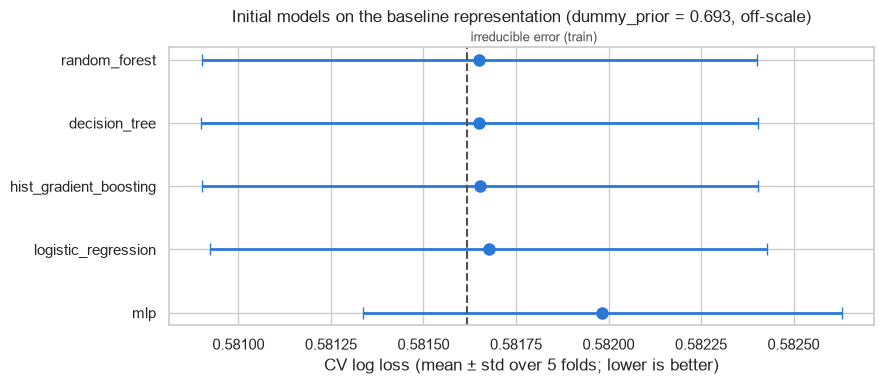

,log_loss_mean,log_loss_std,paired_diff_mean,paired_diff_std,within_1_SE_of_best
model,,,,,
random_forest,0.58165,0.00075,0.00000,0.00000,True
decision_tree,0.58165,0.00075,0.00000,0.00000,True
hist_gradient_boosting,0.58165,0.00075,0.00000,0.00000,True
logistic_regression,0.58168,0.00075,0.00003,0.00001,True
mlp,0.58198,0.00065,0.00033,0.00020,True
dummy_prior,0.69261,0.00005,0.11096,0.00079,False


In [9]:
best_initial = initial_results.iloc[0]
standard_error = best_initial["log_loss_std"] / np.sqrt(N_FOLDS)
baseline_folds = FOLD_LOG_LOSS[(BASELINE_REPRESENTATION, best_initial["model"], "initial")]
paired = pd.DataFrame({
    model: FOLD_LOG_LOSS[(BASELINE_REPRESENTATION, model, "initial")] - baseline_folds
    for model in initial_results["model"]
}).agg(["mean", "std"]).T.rename(columns={"mean": "paired_diff_mean", "std": "paired_diff_std"})
summary = initial_results.set_index("model")[["log_loss_mean", "log_loss_std"]].join(paired)
summary["within_1_SE_of_best"] = summary["log_loss_mean"] <= best_initial["log_loss_mean"] + standard_error
print(f"Best initial: {best_initial['model']} ({best_initial['log_loss_mean']:.5f}); one standard error = "
      f"{standard_error:.5f}; irreducible = {IRREDUCIBLE_LOG_LOSS:.5f}")

plot_data = initial_results[initial_results["model"] != "dummy_prior"].iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 4))
ax.errorbar(plot_data["log_loss_mean"], plot_data["model"], xerr=plot_data["log_loss_std"], fmt="o",
            color=SERIES_1, ecolor=SERIES_1, elinewidth=2, capsize=4, markersize=8)
ax.axvline(IRREDUCIBLE_LOG_LOSS, color=INK_MUTED, linestyle="--", linewidth=1.5)
ax.text(IRREDUCIBLE_LOG_LOSS, 1.01, " irreducible error (train)", transform=ax.get_xaxis_transform(),
        color=INK_MUTED, fontsize=9, va="bottom")
ax.set_xlabel("CV log loss (mean ± std over 5 folds; lower is better)")
dummy_value = initial_results.set_index("model").loc["dummy_prior", "log_loss_mean"]
ax.set_title(f"Initial models on the baseline representation (dummy_prior = {dummy_value:.3f}, off-scale)", pad=18)
plt.tight_layout()
plt.show()
summary

**Interpretation.**
- Every candidate beats the naive reference by a wide margin: from **0.6926** (`dummy_prior`) to **≈ 0.5817**, a 16%
  reduction of log loss, and they all sit within **0.0004** of the irreducible error measured in-sample on train
  (0.58162). The information in `material` + `composter_empty` is fully extracted by any reasonable model.
- The tree family (`random_forest`, `decision_tree`, `hist_gradient_boosting`) ties at **0.58165**: with one-hot inputs
  they all learn the empirical success rate of each cell — the unrestricted tree *is* the lookup table "1 if the
  composter is empty, else the material's training chance" proposed as a baseline in notebook 02 (hypothesis 4). `logistic_regression` is 0.00003 higher, consistently in
  every fold (paired difference 0.00003 ± 0.00001): its L2 penalty (`C=1`) keeps the empty-composter coefficient
  finite, so it predicts ≈ 0.9997 instead of 1 for those attempts (measured in Section 7). The `mlp` is 0.00033 ± 0.00020 higher in paired terms — its
  stochastic optimization stops slightly away from the exact cell rates.
- The fold-to-fold standard deviation (0.00075, one standard error 0.00034) is shared by all models — some folds
  simply contain more random outcomes — so **all five candidates are within one standard error of the best**. No
  model is better than another beyond the uncertainty of the validation.
- Cost differs much more than quality: about 1 s per fold for the tree and the logistic regression, ≈ 6–10 s for
  gradient boosting, ≈ 25–27 s for the random forest and ≈ 36–46 s for the MLP (timings vary between executions).

**Candidates for tuning:** `hist_gradient_boosting` (the richest hyperparameter space at a low cost per trial) and
`mlp` (the only candidate with a consistent gap to close). The reasons and the budget are given in Section 7.

## 6.2 Feature Ablation Study

**Motivation.** Notebook 02 left the representation of the material as a hypothesis. An ablation study evaluates
every variant with every non-trivial model on the same folds, so a difference can be attributed to the features. The
variant is chosen as in the course laboratory: compute the best mean CV log loss of each variant; among the variants
within **one standard error** of the overall best, keep the **simplest** (complexity order: `material_no_empty` <
`material` < `tier` = `chance`, the last two being target encodings).

In [10]:
REPRESENTATION_COMPLEXITY = {"material_no_empty": 0, "material": 1, "tier": 2, "chance": 2}
candidate_models = [name for name in MODELS if name != "dummy_prior"]
ablation_rows = [row for row in initial_rows if row["model"] != "dummy_prior"]          # baseline already done
ablation_rows += [evaluate_cv(name, MODELS[name], representation)
                  for representation in REPRESENTATIONS if representation != BASELINE_REPRESENTATION
                  for name in candidate_models]
ablation_results = pd.DataFrame(ablation_rows)

best_per_variant = (ablation_results.sort_values("log_loss_mean").groupby("representation").first()
                    [["model", "log_loss_mean", "log_loss_std"]]
                    .rename(columns={"model": "best_model", "log_loss_mean": "best_log_loss",
                                     "log_loss_std": "best_log_loss_std"}))
best_per_variant["mean_over_models"] = ablation_results.groupby("representation")["log_loss_mean"].mean()
best_per_variant["complexity"] = best_per_variant.index.map(REPRESENTATION_COMPLEXITY)
best_per_variant = best_per_variant.sort_values("best_log_loss")

overall_best = best_per_variant.iloc[0]
variant_threshold = overall_best["best_log_loss"] + overall_best["best_log_loss_std"] / np.sqrt(N_FOLDS)
best_per_variant["within_1_SE"] = best_per_variant["best_log_loss"] <= variant_threshold
SELECTED_REPRESENTATION = (best_per_variant[best_per_variant["within_1_SE"]]
                           .sort_values(["complexity", "best_log_loss"]).index[0])
print(f"Best raw variant: {best_per_variant.index[0]} ({overall_best['best_log_loss']:.5f}); "
      f"1-SE threshold: {variant_threshold:.5f}")
print(f"Selected representation (performance + parsimony): {SELECTED_REPRESENTATION}")
best_per_variant

Best raw variant: tier (0.58164); 1-SE threshold: 0.58198
Selected representation (performance + parsimony): material


,best_model,best_log_loss,best_log_loss_std,mean_over_models,complexity,within_1_SE
representation,,,,,,
tier,random_forest,0.58164,0.00075,0.58194,2,True
material,random_forest,0.58165,0.00075,0.58172,1,True
chance,logistic_regression,0.58167,0.00075,0.58182,2,True
material_no_empty,hist_gradient_boosting,0.62994,0.00079,0.63004,0,False


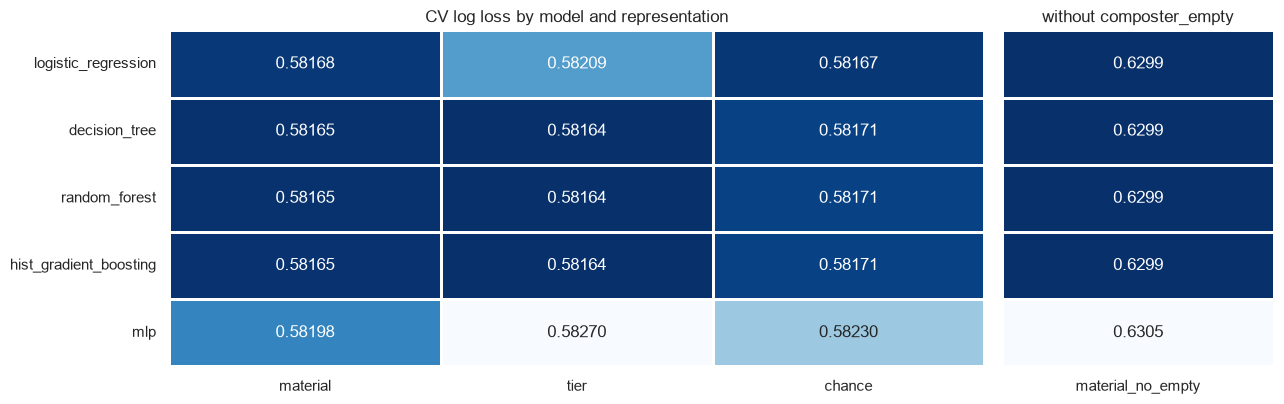

In [11]:
ablation_pivot = ablation_results.pivot(index="model", columns="representation", values="log_loss_mean")
ablation_pivot = ablation_pivot.loc[candidate_models, ["material", "tier", "chance", "material_no_empty"]]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [3, 1]})
sns.heatmap(ablation_pivot.drop(columns="material_no_empty"), annot=True, fmt=".5f", cmap="Blues_r", cbar=False,
            linewidths=2, linecolor="white", ax=axes[0])
axes[0].set_title("CV log loss by model and representation")
axes[0].set_xlabel("")
axes[0].set_ylabel("")
sns.heatmap(ablation_pivot[["material_no_empty"]], annot=True, fmt=".4f", cmap="Blues_r", cbar=False,
            linewidths=2, linecolor="white", ax=axes[1], yticklabels=False)
axes[1].set_title("without composter_empty")
axes[1].set_xlabel("")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

**Interpretation.**
- **`composter_empty` is the most valuable feature.** Without it the best log loss rises from 0.5816 to **0.6299**
  (+0.048, about 64 times the fold standard deviation): the empty-composter rule found in the EDA is the strongest signal available, and
  every model needs it.
- **The three encodings of the material are equivalent.** `tier` (0.58164), `material` (0.58165) and `chance`
  (0.58167) differ by about 0.00003 — a tenth of a standard error. `tier` is marginally best because pooling the
  materials of a tier (for example the six ≈ 30% materials) estimates their common chance with less noise, but the
  gain is far below the variation between folds.
- **Model–representation interactions are visible only where expected.** The ordinal `tier` hurts the logistic
  regression (0.58209), which forces equal logit steps between tiers whose chances (0.30, 0.50, 0.65, 0.85) are not
  equally spaced, and the MLP is worst on the single-column encodings.
- **Decision.** All three encodings are within one standard error (threshold 0.58198), so the rule keeps the
  simplest one: the **baseline `material` (one-hot) + `composter_empty`**, which needs no target encoding. As in the
  course laboratory, a feature engineering idea that is reasonable (and here even marginally better in raw score) is
  not adopted when its advantage is not distinguishable from noise.

## 6.3 Sensitivity to the Sugar Cane Anomaly

**Motivation.** Notebook 02 kept the 60 `Sugar Cane` sessions with `trial_id` 339–398 that behave like a 30%
material, and asked for results with and without them. Here the anomalous sessions are removed **only from the
training part of each fold**; the validation parts stay identical, so the comparison is paired and test is not
involved. Out-of-fold predictions show the effect overall, on the normal `Sugar Cane` sessions and on the anomalous
ones.

In [12]:
anomaly_material, anomaly_first, anomaly_last = SUGAR_CANE_ANOMALY
anomalous_sessions = set(train_sessions.loc[(train_sessions["material"] == anomaly_material)
                                            & train_sessions["trial_id"].between(anomaly_first, anomaly_last),
                                            "session_id"])
is_anomalous_row = X_train["session_id"].isin(anomalous_sessions).to_numpy()
folds_without_anomaly = [(train_idx[~is_anomalous_row[train_idx]], val_idx) for train_idx, val_idx in CV_FOLDS]
is_sugar_cane = (X_train["material"] == anomaly_material).to_numpy()
segments = {"all attempts": np.ones(len(X_train), bool),
            "Sugar Cane, normal sessions": is_sugar_cane & ~is_anomalous_row,
            "Sugar Cane, anomalous sessions": is_anomalous_row}

sensitivity = []
for model in ["logistic_regression", "hist_gradient_boosting"]:
    for training, folds in [("with anomaly (kept)", CV_FOLDS), ("without anomaly", folds_without_anomaly)]:
        proba = cross_val_predict(build_model_pipeline(MODELS[model], SELECTED_REPRESENTATION), X_train, y_train,
                                  cv=folds, method="predict_proba", n_jobs=N_JOBS)[:, 1]
        row = {"model": model, "training data": training}
        row.update({segment: log_loss(y_train[mask], proba[mask]) for segment, mask in segments.items()})
        row["predicted Sugar Cane chance (non-empty)"] = proba[is_sugar_cane & (X_train["attempt_number"] != 1).to_numpy()].mean()
        sensitivity.append(row)
print(f"Anomalous training sessions: {len(anomalous_sessions)} ({is_anomalous_row.sum():,} attempts)")
pd.DataFrame(sensitivity).set_index(["model", "training data"])

Anomalous training sessions: 50 (1,099 attempts)


all attempts  Sugar Cane, normal sessions  Sugar Cane, anomalous sessions  \
model                  training data                                                                                    
logistic_regression    with anomaly (kept)       0.58168                      0.64000                         0.65565   
                       without anomaly           0.58168                      0.63991                         0.66134   
hist_gradient_boosting with anomaly (kept)       0.58165                      0.63999                         0.65531   
                       without anomaly           0.58166                      0.63988                         0.66124   

                                            predicted Sugar Cane chance (non-empty)  
model                  training data                                                 
logistic_regression    with anomaly (kept)                                  0.49231  
                       without anomaly                                      0.49973  
hist_gradient_boosting with anomaly (kept)                                  0.49197  
                       without anomaly                                      0.49962

**Interpretation.** Removing the 50 anomalous training sessions (1,099 attempts) moves the learned `Sugar Cane` chance
from **0.492 to 0.500**. That improves the log loss of the normal `Sugar Cane` sessions by only 0.0001 and worsens the
anomalous ones by 0.006, while the overall log loss does not change at the fifth decimal (0.58168 for the logistic
regression, 0.58165–0.58166 for gradient boosting). The results are therefore **not sensitive** to the anomaly, and
decision D11 of notebook 02 is confirmed: the rows are kept, since the error cannot be proven and removing them buys
nothing measurable.

# 7. Hyperparameter Tuning with Optuna

**Which candidates and why.** Tuning is applied only after fixing the representation (Section 6.2), and only to two
candidates:

- **`HistGradientBoostingClassifier`** — the family with the richest set of interacting hyperparameters and the
  usual tuning candidate for tabular data; one CV run costs seconds, so a real search is affordable.
- **`MLPClassifier`** — the only candidate whose initial score is clearly above the others (Section 6), i.e. the only
  one where tuning has room to matter; one CV run of its initial configuration costs ≈ 45–55 s, so its budget is smaller.

The unrestricted `DecisionTreeClassifier` already *is* the table of cell rates: depth or leaf limits can only merge
cells. `RandomForestClassifier` is the slowest of the trees and is not better than a single tree here.
`LogisticRegression` has a single relevant hyperparameter, `C`, and its only gap to the trees (0.00003) has a known
cause, the L2 penalty; a study is unnecessary, so the next cell measures that one effect directly with the same
folds and the same acceptance rule used for the studies.

**Design of each study.**

| Element | Decision |
|---|---|
| Objective | mean **log loss** over the same 5 folds (`cross_validate` of the complete pipeline inside every trial) |
| Direction | `minimize` |
| Sampler | `TPESampler(seed=42)` (HGB) / `seed=43, n_startup_trials=5` (MLP: 5 random trials, then 10 guided) |
| Budget | **30 trials (HGB), 15 trials (MLP)**. A 30-minute timeout per study is only a safety net: if it fired, the number of trials — and the result — would depend on the machine, so the notebook reports it |
| Starting point | trial 0 is the **initial configuration** (`enqueue_trial`), so the study is compared against it under exactly the same protocol |
| Pruning | not used: the 5 folds of a trial run in parallel, so a trial costs about one fit; pruning needs sequential folds and would make every trial ≈ 5 times slower |

**Search spaces** (only parameters that change what the model can represent):

| Model | Parameter | Range | Reason |
|---|---|---|---|
| HGB | `learning_rate` | 0.01–0.3 (log) | step size; interacts with `max_iter` |
| HGB | `max_iter` | 50–500 (step 50) | number of boosting rounds (early stopping is off) |
| HGB | `max_leaf_nodes` | 4–64 (log) | with fewer than 17 leaves one tree cannot separate the 17 cells; boosting must compensate with more rounds |
| HGB | `min_samples_leaf` | 20–5,000 (log) | large values force each leaf to pool many rows (one material's empty-composter attempts are ≈ 1,900 per fold) |
| HGB | `l2_regularization` | 1e-6–10 (log) | shrinks leaf values; log scale covers "none" to "strong" |
| MLP | architecture | 16, 32, 64, 32-16, 64-32 | capacity, from the smallest that can fit 32 cells to the initial one |
| MLP | `alpha` | 1e-6–1e-1 (log) | L2 penalty |
| MLP | `learning_rate_init` | 1e-4–1e-2 (log) | Adam step size |
| MLP | `batch_size` | 256, 512, 1024 | larger batches are faster on 444,000 rows |

**Where tuning can be treacherous here, and the controls.** The differences between configurations are of the order
of 1e-5–1e-4 in log loss, smaller than the fold-to-fold variation. A search that keeps the minimum of many noisy
evaluations is biased in its own favor (the *winner's curse*). Three controls: (1) the initial configuration is trial
0; (2) the tuned configuration is re-evaluated with the same `evaluate_cv` as every other model, and compared fold by
fold with its initial version; (3) both are re-evaluated on a **second, independent fold partition** (seed 43) that
the search never saw. Tuning is accepted only if the gain is larger than one standard error and survives (3).

In [13]:
lr_rows = [evaluate_cv("logistic_regression", LogisticRegression(C=C, max_iter=1_000), SELECTED_REPRESENTATION,
                       stage=f"C={C:g}") for C in [1.0, 10.0, 100.0]]
lr_initial_folds = FOLD_LOG_LOSS[(SELECTED_REPRESENTATION, "logistic_regression", "C=1")]
check(np.allclose(lr_initial_folds, FOLD_LOG_LOSS[(SELECTED_REPRESENTATION, "logistic_regression", "initial")]),
      "C=1 reproduces the initial logistic regression")
lr_check = pd.DataFrame([{
    "C": row["stage"], "CV log loss": row["log_loss_mean"], "std": row["log_loss_std"],
    "gain vs. C=1": f"{lr_initial_folds.mean() - row['log_loss_mean']:+.1e}",
    "one SE of C=1": f"{lr_initial_folds.std() / np.sqrt(N_FOLDS):.1e}",
} for row in lr_rows]).set_index("C")
lr_check

,CV log loss,std,gain vs. C=1,one SE of C=1
C,,,,
C=1,0.58168,0.00075,+0.0e+00,3.4e-04
C=10,0.58165,0.00075,+2.2e-05,3.4e-04
C=100,0.58165,0.00075,+2.3e-05,3.4e-04


**Interpretation.** A weaker penalty closes the gap exactly as expected: with `C=10` the logistic regression reaches
0.58165, the score of the trees, and `C=100` adds nothing more. The gain, **2.2e-5**, is about 15 times smaller than one
standard error (3.4e-4), so by the acceptance rule of this section it is not a relevant improvement and the logistic
regression keeps its initial `C=1`. The check also confirms the explanation given in Section 6: the only thing
separating the logistic regression from the cell rates is the L2 penalty on the empty-composter coefficient.


In [14]:
def cv_log_loss(trial, estimator):
    """Mean log loss of the complete pipeline on the shared folds (lower is better); also stores the fold spread."""
    scores = cross_validate(build_model_pipeline(estimator, SELECTED_REPRESENTATION), X_train, y_train,
                            cv=CV_FOLDS, scoring="neg_log_loss", n_jobs=N_JOBS)
    fold_losses = -scores["test_score"]
    trial.set_user_attr("log_loss_std", float(fold_losses.std()))
    trial.set_user_attr("fit_time_s", float(scores["fit_time"].mean()))
    return float(fold_losses.mean())


def hgb_objective(trial):
    params = {
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "max_iter": trial.suggest_int("max_iter", 50, 500, step=50),
        "max_leaf_nodes": trial.suggest_int("max_leaf_nodes", 4, 64, log=True),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 20, 5_000, log=True),
        "l2_regularization": trial.suggest_float("l2_regularization", 1e-6, 10.0, log=True),
    }
    return cv_log_loss(trial, make_hgb(params))


def mlp_objective(trial):
    params = {
        "architecture": trial.suggest_categorical("architecture", list(MLP_ARCHITECTURES)),
        "alpha": trial.suggest_float("alpha", 1e-6, 1e-1, log=True),
        "learning_rate_init": trial.suggest_float("learning_rate_init", 1e-4, 1e-2, log=True),
        "batch_size": trial.suggest_categorical("batch_size", [256, 512, 1024]),
    }
    return cv_log_loss(trial, make_mlp(params))


def run_study(name, objective, initial_params, n_trials, sampler):
    study = optuna.create_study(direction="minimize", sampler=sampler, study_name=name)
    study.enqueue_trial(initial_params)
    start = time.perf_counter()
    study.optimize(objective, n_trials=n_trials, timeout=STUDY_TIMEOUT_S, show_progress_bar=False)
    elapsed = time.perf_counter() - start
    completed = sum(t.state == optuna.trial.TrialState.COMPLETE for t in study.trials)
    if completed < n_trials:
        print(f"WARNING: {name} stopped by the timeout after {completed}/{n_trials} trials")
    print(f"{name}: {completed} trials in {elapsed / 60:.1f} min | initial (trial 0) {study.trials[0].value:.5f} | "
          f"best (trial {study.best_trial.number}) {study.best_value:.5f}")
    return study, elapsed


# l2_regularization = 0 is outside a log scale; 1e-6 is the closest value of the space (numerically identical here).
hgb_study, hgb_elapsed = run_study("hist_gradient_boosting", hgb_objective,
                                   {**HGB_INITIAL, "l2_regularization": 1e-6}, HGB_TRIALS,
                                   optuna.samplers.TPESampler(seed=RANDOM_STATE))

hist_gradient_boosting: 30 trials in 10.9 min | initial (trial 0) 0.58165 | best (trial 19) 0.58165


In [15]:
mlp_study, mlp_elapsed = run_study("mlp", mlp_objective, MLP_INITIAL, MLP_TRIALS,
                                   optuna.samplers.TPESampler(seed=RANDOM_STATE + 1, n_startup_trials=5))

mlp: 15 trials in 5.9 min | initial (trial 0) 0.58198 | best (trial 0) 0.58198


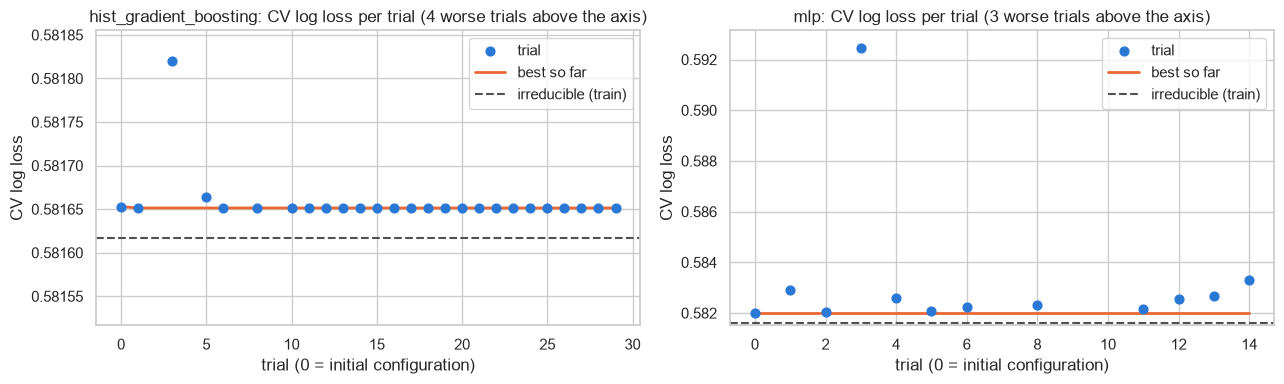

,trials,minutes,initial (trial 0),best,best trial,best - initial,std of best over folds,trials within 1e-4 of best
model,,,,,,,,
hist_gradient_boosting,30,10.86447,0.58165,0.58165,19,-1.6e-06,0.00075,25
mlp,15,5.87087,0.58198,0.58198,0,+0.0e+00,0.00065,2


hist_gradient_boosting: the 3 worst trials


,value,params_l2_regularization,params_learning_rate,params_max_iter,params_max_leaf_nodes,params_min_samples_leaf
number,,,,,,
2,0.61064,0.09047,0.01700,50,44,547
9,0.59735,0.00006,0.01514,250,4,3024
7,0.58408,5.74678,0.07896,100,4,3766


mlp: the 3 worst trials


,value,params_alpha,params_architecture,params_batch_size,params_learning_rate_init
number,,,,,
10,0.59806,0.09890,16,512,0.00021
9,0.59542,0.00200,64_32,1024,0.00018
7,0.59486,0.00000,32,512,0.00013


,hist_gradient_boosting,mlp
learning_rate,0.20868,NaN
max_iter,350.00000,NaN
max_leaf_nodes,40.00000,NaN
min_samples_leaf,31.00000,NaN
l2_regularization,0.00001,NaN
architecture,NaN,64_32
alpha,NaN,0.00010
learning_rate_init,NaN,0.00100
batch_size,NaN,256


In [16]:
STUDIES = {"hist_gradient_boosting": (hgb_study, hgb_elapsed), "mlp": (mlp_study, mlp_elapsed)}
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (name, (study, _)) in zip(axes, STUDIES.items()):
    history = study.trials_dataframe(attrs=("number", "value"))
    ax.scatter(history["number"], history["value"], color=SERIES_1, s=40, label="trial", zorder=3)
    ax.plot(history["number"], history["value"].cummin(), color=SERIES_2, linewidth=2, label="best so far")
    ax.axhline(IRREDUCIBLE_LOG_LOSS, color=INK_MUTED, linestyle="--", linewidth=1.5, label="irreducible (train)")
    y_max = max(np.quantile(history["value"], 0.8), history["value"].iloc[0]) + 0.0002
    hidden = int((history["value"] > y_max).sum())
    ax.set_ylim(IRREDUCIBLE_LOG_LOSS - 0.0001, y_max)
    ax.set_title(f"{name}: CV log loss per trial ({hidden} worse trials above the axis)")
    ax.set_xlabel("trial (0 = initial configuration)")
    ax.set_ylabel("CV log loss")
    ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

study_summary = pd.DataFrame([{
    "model": name, "trials": len(study.trials), "minutes": elapsed / 60,
    "initial (trial 0)": study.trials[0].value, "best": study.best_value, "best trial": study.best_trial.number,
    "best - initial": f"{study.best_value - study.trials[0].value:+.1e}",
    "std of best over folds": study.best_trial.user_attrs["log_loss_std"],
    "trials within 1e-4 of best": sum(t.value <= study.best_value + 1e-4 for t in study.trials),
} for name, (study, elapsed) in STUDIES.items()]).set_index("model")
display(study_summary)
for name, (study, _) in STUDIES.items():
    print(f"{name}: the 3 worst trials")
    display(study.trials_dataframe(attrs=("number", "value", "params")).nlargest(3, "value").set_index("number"))
pd.DataFrame({name: study.best_params for name, (study, _) in STUDIES.items()})

**Interpretation.**
- **Gradient boosting** (30 trials, ≈ 11–23 min depending on the execution): the landscape is flat — **25 of 30 trials
  are within 1e-4 of the best**. The best configuration (trial 19: `learning_rate` 0.21, `max_iter` 350,
  `max_leaf_nodes` 40, `min_samples_leaf` 31) improves on the initial one by **1.6e-6** in log loss. The three worst trials
  all learn too little to reach the 17 cell rates: trial 2 (0.6106) combines a small step (0.017) with only 50
  rounds, and trials 9 and 7 (0.5974, 0.5841) use trees of only 4 leaves — each round can adjust just 4 groups of
  cells — with a small step (0.015) or only 100 rounds. No setting can
  do better than the per-cell rates that the initial configuration already learns.
- **MLP** (15 trials, ≈ 6–9 min): **no sampled configuration beats the initial one** (trial 0 remains the best). The
  worst trials (0.5949–0.5981) share a small initial step (≈ 1e-4–2e-4 against the initial 1e-3), so their training
  ends (early stopping or the 200-epoch limit) before the network reaches the cell rates. Fifteen trials explore little of the space, but the
  margin to the irreducible error is only 0.00036, so even a perfect MLP would merely tie the simpler models.
- The budget was fixed before the search and the 30-minute timeout was never reached, so the result is reproducible.


**Was the budget enough? (convergence check).** The budget was fixed before the search, so it is not changed
after seeing the results; instead, the same studies are read at intermediate checkpoints. Because the sampler is seeded
and trials run one after another, each new proposal depends only on the seed and the previous trials: the first *k*
trials of a study are exactly the study that a budget of *k* trials would have produced. Each checkpoint therefore
shows, at no extra cost, what a smaller budget would have found and how long it would have taken.

In [17]:
CHECKPOINTS = {"hist_gradient_boosting": [10, 20, HGB_TRIALS], "mlp": [5, 10, MLP_TRIALS]}
convergence = []
for name, (study, _) in STUDIES.items():
    trials = study.trials
    for k in CHECKPOINTS[name]:
        first_k = trials[:k]
        best_k = min(first_k, key=lambda t: t.value)
        convergence.append({
            "model": name, "budget (trials)": k,
            "best trial": best_k.number, "best CV log loss": best_k.value,
            "gap to final best": f"{best_k.value - study.best_value:+.1e}",
            "same best configuration": best_k.params == study.best_params,
            "minutes": (first_k[-1].datetime_complete - trials[0].datetime_start).total_seconds() / 60,
        })
convergence = pd.DataFrame(convergence).set_index(["model", "budget (trials)"])
for name, (study, _) in STUDIES.items():
    check(convergence.loc[(name, CHECKPOINTS[name][-1]), "same best configuration"],
          f"{name}: the last checkpoint reproduces the study's best configuration")
convergence

best trial  best CV log loss gap to final best  same best configuration  minutes
model                  budget (trials)                                                                                  
hist_gradient_boosting 10                        1           0.58165          +3.5e-10                    False  2.08209
                       20                       19           0.58165          +0.0e+00                     True  6.61216
                       30                       19           0.58165          +0.0e+00                     True 10.86447
mlp                    5                         0           0.58198          +0.0e+00                     True  2.19191
                       10                        0           0.58198          +0.0e+00                     True  4.21435
                       15                        0           0.58198          +0.0e+00                     True  5.87086

**Interpretation.**
- **Gradient boosting:** the first 10 trials are the sampler's random start-up phase, and their best (trial 1) is
  already within 3.5e-10 of the final best — a different configuration with a numerically identical score. By trial
  20 the search has found **exactly the final best configuration (trial 19)**; the last 10 trials add nothing and cost
  about 40% of the study's time (≈ 4 of ≈ 11 min in this execution).
- **MLP:** the initial configuration is the best at every checkpoint.
- **Budget decision.** Both searches stopped improving well before the end, so the budget was sufficient. A budget of
  20 trials for gradient boosting (the value used in the course's Titanic example) would have given the same result
  in about 35–40% less time, and is a reasonable budget for future executions. It is not adopted here because the budget
  was fixed before the search: lowering it after seeing that it does not change the result would choose the budget
  with the results themselves. That 20 trials suffice is also partly luck (the best trial happened to be number 19);
  what does not depend on luck is that **no budget can matter much**, since the initial model is only 0.00003 above
  the irreducible error, ten times less than one standard error.


# 8. Initial vs. Tuned Models

**Motivation.** The best trial is the minimum of many noisy evaluations, so it must be compared with its initial
configuration under the same protocol, fold by fold, and then checked on folds the search never used.

In [18]:
TUNED_MODELS = {
    "hist_gradient_boosting": make_hgb(hgb_study.best_params),
    "mlp": make_mlp(mlp_study.best_params),
}
tuned_rows = [evaluate_cv(name, estimator, SELECTED_REPRESENTATION, stage="tuned")
              for name, estimator in TUNED_MODELS.items()]
for row in tuned_rows:
    check(np.isclose(row["log_loss_mean"], STUDIES[row["model"]][0].best_value, rtol=0, atol=1e-12),
          f"{row['model']}: re-evaluation reproduces the best trial exactly (same protocol)")

CONFIRMATION_FOLDS = make_session_folds(train_sessions, X_train, N_FOLDS, RANDOM_STATE + 1)
before_after = []
for name, tuned in TUNED_MODELS.items():
    initial_folds = FOLD_LOG_LOSS[(SELECTED_REPRESENTATION, name, "initial")]
    tuned_folds = FOLD_LOG_LOSS[(SELECTED_REPRESENTATION, name, "tuned")]
    confirm_initial = evaluate_cv(name, MODELS[name], SELECTED_REPRESENTATION, folds=CONFIRMATION_FOLDS)
    confirm_tuned = evaluate_cv(name, tuned, SELECTED_REPRESENTATION, folds=CONFIRMATION_FOLDS)
    before_after.append({
        "model": name,
        "initial CV": initial_folds.mean(), "tuned CV": tuned_folds.mean(),
        "gain (initial - tuned)": initial_folds.mean() - tuned_folds.mean(),
        "one SE of initial": initial_folds.std() / np.sqrt(N_FOLDS),
        "folds improved by > 1e-5": f"{int((tuned_folds < initial_folds - 1e-5).sum())}/{N_FOLDS}",
        "gain on confirmation folds": confirm_initial["log_loss_mean"] - confirm_tuned["log_loss_mean"],
        "fit time initial (s)": pd.DataFrame(initial_rows).set_index("model").loc[name, "fit_time_s"],
        "fit time tuned (s)": next(r["fit_time_s"] for r in tuned_rows if r["model"] == name),
    })
before_after = pd.DataFrame(before_after).set_index("model")
before_after["relevant (> 1 SE and confirmed)"] = (
    (before_after["gain (initial - tuned)"] > before_after["one SE of initial"])
    & (before_after["gain on confirmation folds"] > 0)
)
for column in ["gain (initial - tuned)", "one SE of initial", "gain on confirmation folds"]:
    before_after[column] = before_after[column].map("{:+.1e}".format)
before_after

,initial CV,tuned CV,gain (initial - tuned),one SE of initial,folds improved by > 1e-5,gain on confirmation folds,fit time initial (s),fit time tuned (s),relevant (> 1 SE and confirmed)
model,,,,,,,,,
hist_gradient_boosting,0.58165,0.58165,+1.6e-06,+3.4e-04,0/5,+1.6e-06,6.14058,19.01803,False
mlp,0.58198,0.58198,+0.0e+00,+2.9e-04,0/5,+0.0e+00,36.25617,36.52912,False


**Interpretation.**
- Both re-evaluations reproduce the best trial exactly, so the tuned and initial models were compared under the same
  protocol.
- **Gradient boosting:** the gain is **1.6e-6**, about 200 times smaller than one standard error (3.4e-4); no fold
  improves by more than 1e-5, and on the confirmation folds the search never saw the gain is again only 1.6e-6. In
  exchange, the tuned model takes **≈ 3–4 times longer to fit** (≈ 19–42 s instead of ≈ 6–10 s per fold, depending on the execution).
- **MLP:** Optuna kept the initial configuration, so the tuned model is the initial one; any difference between its two
  fit times (same configuration) only shows the run-to-run variation of timing measurements.
- **Conclusion: tuning did not produce a relevant improvement.** This is the expected outcome when the initial models
  already reach the irreducible error; it shows that tuning is a hypothesis to test, not a guaranteed gain. Neither
  tuned model is preferable to its initial version.

# 9. Final Selection Using Only Cross-Validation

**Motivation.** All initial and tuned pipelines of the selected representation are put in one table measured with the
same protocol. The rule fixed in Section 1 is applied: lowest mean CV log loss, and among the pipelines within one
standard error of it, the simplest (complexity order fixed in Section 1: logistic regression < decision tree < gradient boosting < random
forest < MLP; a tuned configuration counts as slightly more complex than its initial one). Test is not involved.

In [19]:
MODEL_COMPLEXITY = {"logistic_regression": 1, "decision_tree": 2, "hist_gradient_boosting": 3,
                    "random_forest": 4, "mlp": 5}
comparison = pd.concat([
    ablation_results[ablation_results["representation"] == SELECTED_REPRESENTATION],
    pd.DataFrame(tuned_rows),
], ignore_index=True)
comparison["complexity"] = comparison["model"].map(MODEL_COMPLEXITY) + (comparison["stage"] == "tuned") * 0.5
comparison = comparison.sort_values("log_loss_mean").reset_index(drop=True)
selection_threshold = comparison.loc[0, "log_loss_mean"] + comparison.loc[0, "log_loss_std"] / np.sqrt(N_FOLDS)
comparison["within_1_SE"] = comparison["log_loss_mean"] <= selection_threshold
selected = comparison[comparison["within_1_SE"]].sort_values(["complexity", "log_loss_mean"]).iloc[0]
SELECTED_MODEL, SELECTED_STAGE = selected["model"], selected["stage"]
selected_estimator = TUNED_MODELS[SELECTED_MODEL] if SELECTED_STAGE == "tuned" else MODELS[SELECTED_MODEL]

print(f"Lowest CV log loss: {comparison.loc[0, 'model']} ({comparison.loc[0, 'stage']}) "
      f"{comparison.loc[0, 'log_loss_mean']:.5f}; one-SE threshold {selection_threshold:.5f}")
print(f"Selected pipeline: representation '{SELECTED_REPRESENTATION}' + {SELECTED_MODEL} ({SELECTED_STAGE}) "
      f"-> CV log loss {selected['log_loss_mean']:.5f} ± {selected['log_loss_std']:.5f}")
comparison[["model", "stage", "log_loss_mean", "log_loss_std", "brier_mean", "roc_auc_mean", "accuracy_mean",
            "fit_time_s", "complexity", "within_1_SE"]]

Lowest CV log loss: random_forest (initial) 0.58165; one-SE threshold 0.58199
Selected pipeline: representation 'material' + logistic_regression (initial) -> CV log loss 0.58168 ± 0.00075


,model,stage,log_loss_mean,log_loss_std,brier_mean,roc_auc_mean,accuracy_mean,fit_time_s,complexity,within_1_SE
0,random_forest,initial,0.58165,0.00075,0.20202,0.72613,0.69048,24.17923,4.00000,True
1,decision_tree,initial,0.58165,0.00075,0.20202,0.72613,0.69068,0.98455,2.00000,True
2,hist_gradient_boosting,tuned,0.58165,0.00075,0.20202,0.72613,0.69068,19.01803,3.50000,True
3,hist_gradient_boosting,initial,0.58165,0.00075,0.20202,0.72613,0.69068,6.14058,3.00000,True
4,logistic_regression,initial,0.58168,0.00075,0.20202,0.72613,0.69068,1.02161,1.00000,True
5,mlp,initial,0.58198,0.00065,0.20217,0.72521,0.68994,36.25617,5.00000,True
6,mlp,tuned,0.58198,0.00065,0.20217,0.72521,0.68994,36.52912,5.50000,True


In [20]:
final_pipeline = build_model_pipeline(selected_estimator, SELECTED_REPRESENTATION)
start = time.perf_counter()
final_pipeline.fit(X_train, y_train)
print(f"Final pipeline fitted on all {len(X_train):,} training attempts in {time.perf_counter() - start:.1f} s")
display(final_pipeline)

model = final_pipeline.named_steps["model"]
coefficients = pd.Series(model.coef_[0], index=final_pipeline[:-1].get_feature_names_out())
material_coefficients = coefficients.filter(like="nominal__material_")
readable = pd.DataFrame({
    "coefficient (log-odds)": material_coefficients.to_numpy(),
    "chance, non-empty composter": 1 / (1 + np.exp(-(model.intercept_[0] + material_coefficients.to_numpy()))),
}, index=material_coefficients.index.str.removeprefix("nominal__material_")).sort_values("chance, non-empty composter")
print(f"Intercept {model.intercept_[0]:.3f} | composter_empty coefficient {coefficients['binary__composter_empty']:.3f}")
readable

Final pipeline fitted on all 555,828 training attempts in 0.7 s


Pipeline(steps=[('composter_empty',
                 FunctionTransformer(feature_names_out=<function composter_empty_names at 0x00000171F178A020>,
                                     func=<function add_composter_empty at 0x00000171F17885E0>)),
                ('columns',
                 ColumnTransformer(transformers=[('nominal',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['material']),
                                                 ('binary', 'passthrough',
                                                  ['composter_empty'])])),
                ('model', LogisticRegression(max_iter=1000))])

Intercept 0.059 | composter_empty coefficient 8.376


,coefficient (log-odds),"chance, non-empty composter"
Pumpkin Seeds,-0.92033,0.29715
Oak Sapling,-0.91197,0.29890
Melon Seeds,-0.91151,0.29900
Oak Leaves,-0.90079,0.30125
Wheat Seeds,-0.88816,0.30392
Radish Seeds,-0.88629,0.30431
Sugar Cane,-0.08949,0.49249
Cactus,-0.05013,0.50233
Melon,0.53652,0.64473
Carrot,0.55198,0.64826


**Interpretation.** The lowest mean log loss is the initial random forest's (0.58165); the one-standard-error threshold
is 0.58199 and **all seven pipelines are inside it**. By the rule fixed in Section 1, the simplest is chosen:
**`material` one-hot + `composter_empty` → `LogisticRegression`**, with CV log loss **0.58168 ± 0.00075** (Brier 0.2020,
ROC AUC 0.726, accuracy 0.691). It is preferred over the tied alternatives because:

- it is 0.00003 above the best (0.005% of the loss), a difference no fold variation can make meaningful;
- it fits in about 1 s per fold, against ≈ 6–10 s (gradient boosting), ≈ 25–27 s (random forest) and ≈ 36–46 s (MLP);
- its parameters are readable (table above): the intercept plus one coefficient per material give the log-odds of
  success on a non-empty composter — from 0.30 for the seeds, leaves and sapling to 0.85 for Cookie, the same
  rates found in the EDA — and the empty-composter coefficient (8.4) raises any material to ≈ 0.9997;
- it needs no tuning and no target encoding.

The unrestricted decision tree, which is exactly the lookup table of cell rates, would be an equally defensible choice;
the logistic regression wins only by the order of complexity declared before the comparison. The final pipeline is
fitted once on all 555,828 training attempts (under 1 s).

# 10. Single Evaluation on Test

**Motivation.** Every decision is closed: representation, model, hyperparameters and threshold (0.5). The test
attempts are now transformed and predicted **once**; the following cells only analyze these stored predictions and
none of them feeds back into a decision.

In [21]:
TEST_EVALUATIONS = 0
proba_test = final_pipeline.predict_proba(X_test)[:, 1]
pred_test = (proba_test >= 0.5).astype(int)
TEST_EVALUATIONS += 1

cv_row = selected
test_metrics = pd.DataFrame({
    "CV mean (train, 5 folds)": [cv_row["log_loss_mean"], cv_row["brier_mean"], cv_row["roc_auc_mean"],
                                 cv_row["accuracy_mean"], cv_row["f1_mean"]],
    "CV std": [cv_row["log_loss_std"], cv_row["brier_std"], cv_row["roc_auc_std"], cv_row["accuracy_std"],
               cv_row["f1_std"]],
    "test (single evaluation)": [log_loss(y_test, proba_test), brier_score_loss(y_test, proba_test),
                                 roc_auc_score(y_test, proba_test), accuracy_score(y_test, pred_test),
                                 f1_score(y_test, pred_test)],
}, index=["log loss", "Brier score", "ROC AUC", "accuracy", "F1 (positive class)"])
cell_test = X_test["material"].where(X_test["attempt_number"] != 1, "EMPTY COMPOSTER")
test_metrics.loc["log loss", "irreducible on test (exact test cell rates)"] = log_loss(
    y_test, y_test.groupby(cell_test).transform("mean").clip(1e-15, 1 - 1e-15))
test_metrics

,"CV mean (train, 5 folds)",CV std,test (single evaluation),irreducible on test (exact test cell rates)
log loss,0.58168,0.00075,0.58367,0.58355
Brier score,0.20202,0.00037,0.20290,NaN
ROC AUC,0.72613,0.00068,0.72281,NaN
accuracy,0.69068,0.00151,0.68783,NaN
F1 (positive class),0.65744,0.00862,0.65843,NaN


,precision,recall,f1-score,support
no increase (0),0.68189,0.74616,0.71258,72395.00000
level increased (1),0.69563,0.62500,0.65843,67200.00000
accuracy,0.68783,0.68783,0.68783,0.68783
macro avg,0.68876,0.68558,0.68550,139595.00000
weighted avg,0.68850,0.68783,0.68651,139595.00000


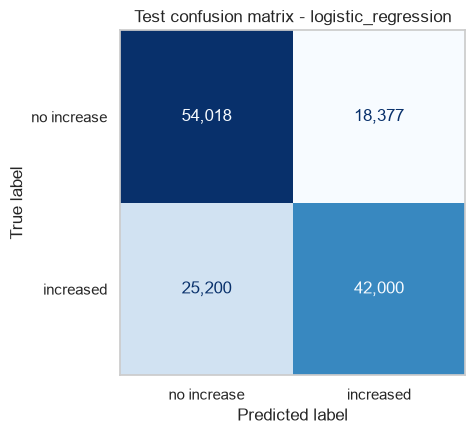

In [22]:
report = pd.DataFrame(classification_report(y_test, pred_test, output_dict=True, zero_division=0,
                                            target_names=["no increase (0)", "level increased (1)"])).T
display(report)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, pred_test, display_labels=["no increase", "increased"],
                                        cmap="Blues", colorbar=False, values_format=",", ax=ax)
ax.set_title(f"Test confusion matrix - {SELECTED_MODEL}")
ax.grid(False)
plt.tight_layout()
plt.show()

**Interpretation.**
- **Log loss on test: 0.58367**, against 0.58168 ± 0.00075 in cross-validation. The difference looks like 2.7 fold
  standard deviations, but the last column explains it: the *irreducible* log loss of the test set itself — the exact
  success rates of its own cells — is **0.58355**. The test sessions simply contain slightly more random outcomes than
  the training ones, and the model is only **0.00012 above the best any model could achieve on them**. There is no
  sign of overfitting.
- Brier (0.2029), accuracy (0.688) and F1 (0.658) are within about 2.5 fold standard deviations of their CV values.
  ROC AUC is 0.003 lower (0.723 vs 0.726, ≈ 5 fold standard deviations): like the log loss, it reflects the
  slightly higher randomness of this sample of sessions, not a different behavior of the model.
- **Confusion matrix.** The 18,377 false positives are failures of materials whose chance is ≥ 0.5 (Cookie, the 65%
  crops, Cactus), and the 25,200 false negatives are successes of materials below 0.5 (seeds, leaves, sapling, Sugar
  Cane). Precision 0.70 and recall 0.63 for "level increased"; 0.68 / 0.75 for "no increase". These errors cannot be
  removed with the available inputs: the same input (material, empty flag) leads to both outcomes.

This is the single evaluation of the selected pipeline; it is reported as it is and does not change any decision.

# 11. Error Analysis

**Motivation.** With only 32 distinct inputs, errors can be understood segment by segment: is the model wrong because
its probabilities are off (calibration), or because the outcome is a coin flip it cannot know? The table compares, on
the test attempts, the predicted chance with the observed success rate for each material (non-empty composter) and
for the empty composter.

Largest |calibration gap| over segments: 0.0140
Sugar Cane anomalous test sessions: 10 (230 attempts), log loss 0.6566 vs 0.5836 on the rest


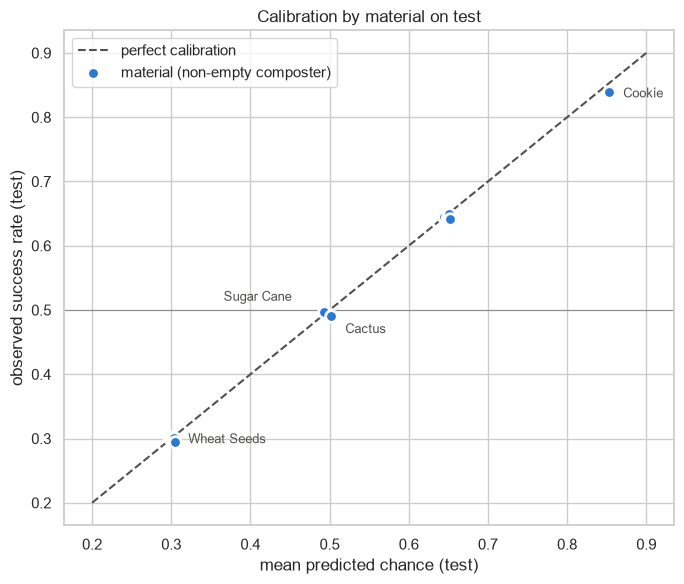

,attempts,predicted_chance,observed_rate,predicted_class,accuracy,calibration_gap,log_loss,best_possible_accuracy
segment,,,,,,,,
Pumpkin Seeds,11917,0.29715,0.30209,0.00000,0.69791,-0.00494,0.61268,0.69791
Oak Sapling,11985,0.29890,0.30038,0.00000,0.69962,-0.00147,0.61119,0.69962
Melon Seeds,11963,0.29900,0.30093,0.00000,0.69907,-0.00193,0.61166,0.69907
Oak Leaves,11968,0.30125,0.30080,0.00000,0.69920,0.00045,0.61154,0.69920
Wheat Seeds,11947,0.30392,0.30133,0.00000,0.69867,0.00259,0.61200,0.69867
Radish Seeds,12194,0.30431,0.29523,0.00000,0.70477,0.00908,0.60696,0.70477
Sugar Cane,7244,0.49249,0.49696,0.00000,0.50304,-0.00447,0.69317,0.50304
Cactus,7348,0.50233,0.48993,1.00000,0.48993,0.01240,0.69325,0.51007
Melon,5584,0.64473,0.64470,1.00000,0.64470,0.00003,0.65067,0.64470


In [23]:
segment = cell_test.rename("segment")
error_table = pd.DataFrame({"segment": segment, "y": y_test.to_numpy(), "p": proba_test, "pred": pred_test})
error_table["correct"] = error_table["y"] == error_table["pred"]
by_segment = error_table.groupby("segment").agg(
    attempts=("y", "size"), predicted_chance=("p", "mean"), observed_rate=("y", "mean"),
    predicted_class=("pred", "mean"), accuracy=("correct", "mean"))
by_segment["calibration_gap"] = by_segment["predicted_chance"] - by_segment["observed_rate"]
by_segment["log_loss"] = error_table.groupby("segment")[["y", "p"]].apply(
    lambda g: log_loss(g["y"], g["p"], labels=[0, 1]))
by_segment["best_possible_accuracy"] = np.maximum(by_segment["observed_rate"], 1 - by_segment["observed_rate"])
by_segment = by_segment.sort_values("predicted_chance")

test_anomalous = set(test_sessions.loc[(test_sessions["material"] == anomaly_material)
                                       & test_sessions["trial_id"].between(anomaly_first, anomaly_last), "session_id"])
anomalous_test_rows = X_test["session_id"].isin(test_anomalous).to_numpy()
print(f"Largest |calibration gap| over segments: {by_segment['calibration_gap'].abs().max():.4f}")
print(f"Sugar Cane anomalous test sessions: {len(test_anomalous)} ({anomalous_test_rows.sum():,} attempts), "
      f"log loss {log_loss(y_test[anomalous_test_rows], proba_test[anomalous_test_rows]):.4f} vs "
      f"{log_loss(y_test[~anomalous_test_rows], proba_test[~anomalous_test_rows]):.4f} on the rest")

materials_only = by_segment.drop(index="EMPTY COMPOSTER")
fig, ax = plt.subplots(figsize=(7, 6))
ax.plot([0.2, 0.9], [0.2, 0.9], color=INK_MUTED, linestyle="--", linewidth=1.5, label="perfect calibration")
ax.scatter(materials_only["predicted_chance"], materials_only["observed_rate"], color=SERIES_1, s=70, zorder=3,
           edgecolor="white", linewidth=2, label="material (non-empty composter)")
label_offsets = {"Cookie": (10, -4), "Cactus": (10, -12), "Sugar Cane": (-72, 8), "Wheat Seeds": (10, -4)}
for name, offset in label_offsets.items():
    ax.annotate(name, (materials_only.loc[name, "predicted_chance"], materials_only.loc[name, "observed_rate"]),
                xytext=offset, textcoords="offset points", fontsize=9, color=INK_MUTED)
ax.axhline(0.5, color=INK_MUTED, linewidth=0.8, alpha=0.5)
ax.set_xlabel("mean predicted chance (test)")
ax.set_ylabel("observed success rate (test)")
ax.set_title("Calibration by material on test")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()
by_segment

**Interpretation.**
- **The probabilities are well calibrated.** For every material the predicted chance is within **0.014** of the
  observed test rate (largest gaps: Cookie 0.853 vs 0.839, Cactus 0.502 vs 0.490, Pumpkin 0.652 vs 0.640), the size
  expected from sampling noise in segments of 4,000–12,000 attempts that are not independent within a session.
- **Accuracy equals the best possible accuracy in every segment but one.** For each material the model predicts the
  more likely class, so its accuracy is $\max(p, 1-p)$ of the observed rate. The exception is **Cactus**: its training
  chance (0.502) is just above 0.5, so the model predicts "increase", while on test it succeeded 49.0% of the time
  (accuracy 0.490 instead of 0.510). Cactus and Sugar Cane are true coin flips (≈ 0.50 accuracy, log loss ≈ 0.693),
  and the seed / leaf / sapling group fails 70% of the time — that is the game's randomness, not a model error.
- **Empty composter:** every attempt is a success and the model predicts 0.9997; the logistic regression cannot
  output exactly 1, which costs a negligible log loss (0.0003) on these attempts.
- **Sugar Cane anomaly:** the 10 anomalous test sessions (230 attempts) have a log loss of 0.657 against 0.584 for the
  rest, because they behave like a 30% material while the model, correctly for normal sessions, predicts ≈ 0.49.
  Nothing in the inputs can reveal such a stretch.

# 12. Final Verifications

**Motivation.** The checks below confirm that the evaluated pipeline is exactly the selected one, that test was used
once, and that nothing from test entered training.

In [24]:
final_checks = [
    check(TEST_EVALUATIONS == 1, "test was predicted exactly once"),
    check(len(proba_test) == len(X_test) and np.isfinite(proba_test).all(), "one finite probability per test attempt"),
    check(set(np.unique(pred_test)) <= {0, 1}, "test predictions are binary"),
    check(type(final_pipeline.named_steps["model"]) is type(selected_estimator), "the final model is the selected one"),
    check(("material_stats" in final_pipeline.named_steps) == NEEDS_MATERIAL_STATS[SELECTED_REPRESENTATION],
          "the final preparation matches the selected representation"),
    check(not set(X_train["session_id"]) & set(X_test["session_id"]), "no test session was used for training"),
    check(not any(c in name for name in final_pipeline[:-1].get_feature_names_out()
                  for c in ["session_id", "attempt_number", "trial_id", "items_used"]),
          "no identifier, synthetic order or future information reaches the model"),
]
print("\n".join(f"  [ok] {msg}" for msg in final_checks))

  [ok] test was predicted exactly once
  [ok] one finite probability per test attempt
  [ok] test predictions are binary
  [ok] the final model is the selected one
  [ok] the final preparation matches the selected representation
  [ok] no test session was used for training
  [ok] no identifier, synthetic order or future information reaches the model


# 13. Conclusions

**Which pipeline was selected?** The baseline representation of notebook 02 — `material` one-hot + `composter_empty`
(`FunctionTransformer → ColumnTransformer(remainder="drop")`) — followed by `LogisticRegression(C=1.0)` with its
initial configuration.

**Mean performance and variation.** CV log loss **0.58168 ± 0.00075** over 5 folds grouped by session (Brier 0.2020,
ROC AUC 0.726, accuracy 0.691, F1 0.657), against 0.6926 for the class prior and 0.58162 for the irreducible error on
train. On the single test evaluation: log loss 0.58367 (test's own irreducible error: 0.58355), Brier 0.2029, ROC AUC
0.723, accuracy 0.688.

**Did tuning help?** No. A weaker penalty for the logistic regression gains 2.2e-5, about 15 times less than one
standard error. Gradient boosting improved by 1.6e-6 (about 200 times less than one standard error, and
the same negligible amount on independent confirmation folds) at three to four times the fitting cost, and no MLP configuration beat the initial one.
The models already reach the irreducible error, so there is nothing left for hyperparameters to recover. The
searches also converged well within their budgets (gradient boosting found its final best by trial 20 of 30).

**Why this pipeline and not a similar one?** All candidates are within one standard error of each other; the
logistic regression is the simplest, as fast as the single tree, interpretable as one log-odds per material,
and needs neither target encoding nor tuning. The decision was taken only with cross-validation on train, by a rule
written before seeing the results.

**What the evidence says about the features.** The empty-composter rule is the decisive feature (+0.048 of log loss
without it). The two target-derived encodings of notebook 02 (`tier`, `chance`) are statistically indistinguishable
from the one-hot material and are not adopted. The `Sugar Cane` anomaly has no measurable effect on the results. The baseline proposed in notebook 02 (the
material's training rate plus the empty-composter rule) is matched by every candidate: it is exactly what the
unrestricted tree learns.

**Limitations.**
- The outcome is mostly the game's randomness: with only the material and the empty flag, about 31% of attempts
  remain misclassified whatever the model; Cactus and Sugar Cane are coin flips.
- The order of the middle attempts of each session is synthetic (notebook 02), so attempt-level labels are one
  random realization; the per-material rates the model learns depend only on observed counts.
- The test set is not fully independent: the EDA examined all sessions before the split.
- The model only generalizes to the 16 known materials; an unseen item would get only the empty-composter effect.
- The anomalous `Sugar Cane` stretch cannot be detected from the inputs.
- Optuna's search for the MLP used 15 trials; with more resources it could be extended, but the measured margin
  (0.00036) bounds any possible gain.

**Process checklist.** Primary metric defined before the comparison (log loss) · grouped CV respecting sessions ·
naive baseline · five candidate models plus one excluded with measured cost · the same folds everywhere · mean and
standard deviation reported · preprocessing fitted inside every fold · Optuna with an explicit objective, space, seed
and budget · tuned vs. initial compared under the same protocol and on confirmation folds · selection without test ·
test evaluated once · errors and limitations interpreted · notebook executed from a restarted kernel.